In [141]:
import torch
from torch import optim
import matplotlib.pyplot as plt

from utils import *

# Optimisation d'une forme quadratique

On voit $X ∈ M_n(ℝ)$ comme un élément de $ℝ^{n^2}$ et on lui applique alors la
forme quadratique $f(X) = \frac{1}{2} ⟨AX, X⟩$, où $A ∈ M_{n^2}(ℝ)$ est
l'identité sauf $A_{1,1} = 100$.

In [142]:
def f(X):
    v = X.flatten()
    A = torch.diag(torch.ones(len(v)))
    A[1, 1] = 100
    return 0.5 * torch.dot(A @ v, v)

In [143]:
#torch.manual_seed(123)

names = ("SGD", "Spectral GD")

variables = [torch.randn(5, 5, requires_grad=True) for _ in names]

optimizers = [
    optim.SGD([variables[0]], lr=2/(100 + 1)), # 2/(L+μ), optimal step size
    spectral_GD(variables[1], lr=0.005)
]

In [144]:
losses = [[] for _ in names]

epochs = 1000
for _ in range(epochs):
    for X, opt, loss in zip(variables, optimizers, losses):
        loss_value = f(X)
        loss.append(loss_value.item())
        loss_value.backward()
        opt.step()
        opt.zero_grad()

for name, loss in zip(names, losses):
    print(f"{name}: final loss = {loss[-1]}")

SGD: final loss = 2.1537396900249748e-16
Spectral GD: final loss = 0.0003260165685787797


J'ai beau avoir optimisé au mieux le pas de la descente spectrale, elle converge
plus lentement que la descente ordinaire et fini par atteindre un plateau avant
le minimum.

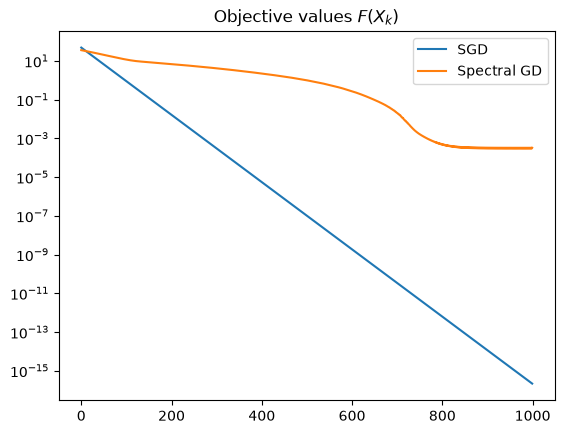

In [145]:
fig, ax = plt.subplots()
ax.set_title("Objective values $F(X_k)$")
ax.set_yscale('log')
for name, loss in zip(names, losses):
    ax.plot(loss, label=name)
ax.legend()

plt.show()